# Site04 registration and point selection

**Status:** Follow-on to `01_site04_data_audit.ipynb`. Local product inspection only. This notebook does not calculate Sun or Earth geometry, does not convert projected metres to latitude/longitude, and does not recommend a landing site.

**Product:** NASA PGDA *High-Resolution LOLA Topography for Lunar South Pole Sites* (Barker et al., 2021), Site04 Shackleton rim.

**Point-label rule:** The first-audit representative point remains `FID 0 / audit point`. It is a temporary test point in an unnamed shapefile record, not a named landing site.


In [1]:
from __future__ import annotations

from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path
import hashlib
import json
import os
import tarfile
import urllib.request

import fiona
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, display
from rasterio.features import rasterize
from rasterio.plot import plotting_extent
from shapely.affinity import translate
from shapely.geometry import Point, mapping, shape
from shapely.ops import unary_union
from shapely.validation import explain_validity

DATA_ROOT = Path("/workspace/data/LOLA_5mpp")
SITE_DIR = DATA_ROOT / "Site04"
ACCESS_DATE_UTC = "2026-11-05"
PRODUCT_PAGE = "https://pgda.gsfc.nasa.gov/products/78"
PRODUCT_README = "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/README"
GMT_NAME = "Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt"
GMT_URL = f"https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/{GMT_NAME}"
PIXEL_M = 5.0

print("notebook_run_utc", datetime.now(timezone.utc).isoformat())
print("access_date_utc", ACCESS_DATE_UTC)
print("site_dir_exists", SITE_DIR.is_dir())


notebook_run_utc 2026-11-05T18:21:41.912232+00:00
access_date_utc 2026-11-05
site_dir_exists True


In [2]:
SOURCES = [
    {
        "file": "README",
        "role": "Product README (units, GMT pixel-registered statement, file meanings)",
        "url": PRODUCT_README,
        "local": DATA_ROOT / "README",
        "expected_sha256": "e985a2337c9de1cd665b0ddad8b7f1fac88d65c96d1e47d1b975a91c8e53e7bd",
    },
    {
        "file": "Site04_ROIs.tgz",
        "role": "ROI shapefile archive",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_ROIs.tgz",
        "local": SITE_DIR / "Site04_ROIs.tgz",
        "expected_sha256": "8e8b788f9fdf6400f23fd36dad02138102bd1a905b4b71a5739a9a4fd8a0e07a",
    },
    {
        "file": "Site04_final_adj_5mpp_surf.tif",
        "role": "Surface height Z (metres)",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_surf.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_surf.tif",
        "expected_sha256": "38ff70dbdf2f066c2cfa94a646c3a59d653ce7f6b4528b15fc1b43ee397ce758",
    },
    {
        "file": "Site04_final_adj_5mpp_toterr.tif",
        "role": "Total Z uncertainty (metres, RMS)",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_toterr.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_toterr.tif",
        "expected_sha256": "416c4baa3b64def0182bb3379a1a9228482efd8ce32a39309ea8de5d0330fbe6",
    },
    {
        "file": "Site04_final_adj_5mpp_ldec.tif",
        "role": "LOLA return count per pixel",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_ldec.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_ldec.tif",
        "expected_sha256": "fcc8c2219ae2368d5b2a1f6aec05fcf96cf725f3035ac8d80efc312a4ff29227",
    },
    {
        "file": "Site04_final_adj_5mpp_slp.tif",
        "role": "Slope (degrees)",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_slp.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_slp.tif",
        "expected_sha256": "ec3cfa184b114d95aff498e7452764a8569737ae829e7ff3efd38d5187182579",
    },
]


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


rows = []
for item in SOURCES:
    path = item["local"]
    actual = sha256_file(path) if path.is_file() else None
    rows.append({
        "file": item["file"],
        "role": item["role"],
        "url": item["url"],
        "access_date_utc": ACCESS_DATE_UTC,
        "bytes": path.stat().st_size if path.is_file() else None,
        "checksum_matches": actual == item["expected_sha256"],
    })

inventory = pd.DataFrame(rows)
display(inventory)
if not inventory["checksum_matches"].all():
    raise SystemExit("One or more local files failed the recorded SHA-256 check.")
print("product_page", PRODUCT_PAGE)


,file,role,url,access_date_utc,bytes,checksum_matches
0,README,"Product README (units, GMT pixel-registered st...",https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/README,2026-11-05,1829,True
1,Site04_ROIs.tgz,ROI shapefile archive,https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site...,2026-11-05,1712,True
2,Site04_final_adj_5mpp_surf.tif,Surface height Z (metres),https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site...,2026-11-05,40980806,True
3,Site04_final_adj_5mpp_toterr.tif,"Total Z uncertainty (metres, RMS)",https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site...,2026-11-05,40980808,True
4,Site04_final_adj_5mpp_ldec.tif,LOLA return count per pixel,https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site...,2026-11-05,40980740,True
5,Site04_final_adj_5mpp_slp.tif,Slope (degrees),https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site...,2026-11-05,40980772,True


product_page https://pgda.gsfc.nasa.gov/products/78


In [3]:
print("Product README (verbatim, registration-relevant lines):")
readme = (DATA_ROOT / "README").read_text(encoding="utf-8", errors="replace")
for line in readme.splitlines():
    if any(token in line.lower() for token in ["pixel", "stereographic", "moon_me", "roi", "ldec", "slope", "interpolat", "site04"]):
        print(line)
print()
print("--- archive listing ---")
with tarfile.open(SITE_DIR / "Site04_ROIs.tgz", "r:gz") as archive:
    for member in archive.getmembers():
        print(f"{member.type} {member.name} size={member.size} link={member.linkname!r}")

gmt_link = SITE_DIR / "Site04_ROIs.gmt"
gmt_target = os.readlink(gmt_link) if gmt_link.is_symlink() else None
print()
print("gmt_symlink", gmt_link.is_symlink())
print("gmt_target", gmt_target)
print("gmt_target_exists_beside_shapefile", bool(gmt_target and (SITE_DIR / gmt_target).exists()))
print("expected_gmt_name_matches_symlink", gmt_target == GMT_NAME)

req = urllib.request.Request(GMT_URL, method="GET")
with urllib.request.urlopen(req, timeout=30) as resp:
    gmt_bytes = resp.read()
    gmt_content_type = resp.headers.get("Content-Type")
    gmt_status = resp.status
print("gmt_url", GMT_URL)
print("gmt_http_status", gmt_status)
print("gmt_content_type", gmt_content_type)
print("gmt_bytes", len(gmt_bytes))
print("gmt_looks_like_html", gmt_bytes.lstrip().startswith(b"<!DOCTYPE") or b"<html" in gmt_bytes[:200].lower())
print("Filename token avgillGT070 is consistent with average illumination > 70%, but the .gmt file is not in the tgz and the URL did not return a GMT file.")


Product README (verbatim, registration-relevant lines):
Each directory contains 5 m/pix GeoTiffs with south polar stereographic X/Y coords in meters, MOON_ME reference frame of ephemeris DE421.
X/Y coords follow the Generic Mapping Tools 'pixel-registered' convention (i.e., they are the centers of the pixels).
*_surf.tif : surface height Z (meters) with interpolation filling empty pix
*_ldec.tif : LDEC map, number of LOLA returns in each pixel
*_slp.tif : Slope (degrees)
*_slperr.tif : Slope uncertainty in degrees (formally, the RMS error)
where X,Y,Z are the polar stereographic coordinates (in km) and RDRid is the LOLA RDR ID for each point with the format: YYDOYHHMM
*_ROIs.tgz - archive containing shapefiles (for GIS)
Site04: Shackleton rim

--- archive listing ---
b'0' Site04_ROIs.dbf size=294 link=''
b'2' Site04_ROIs.gmt size=0 link='Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt'
b'0' Site04_ROIs.prj size=352 link=''
b'0' Site04_ROIs.shp size=5524 link=''
b'0' Site04_ROIs.sh

gmt_url https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt
gmt_http_status 200
gmt_content_type text/html; charset=utf-8
gmt_bytes 3789
gmt_looks_like_html True
Filename token avgillGT070 is consistent with average illumination > 70%, but the .gmt file is not in the tgz and the URL did not return a GMT file.


In [4]:
ROI_SHP = SITE_DIR / "Site04_ROIs.shp"
features = []
with fiona.open(ROI_SHP) as src:
    shapefile_meta = {
        "driver": src.driver,
        "crs_wkt": src.crs_wkt,
        "crs": dict(src.crs) if src.crs else None,
        "schema": src.schema,
        "bounds": src.bounds,
        "n_features": len(src),
    }
    for index, feat in enumerate(src):
        geom = shape(feat["geometry"])
        features.append({
            "fid": index,
            "label": f"FID {index}",
            "geometry": geom,
            "properties": dict(feat["properties"]),
        })

print("shapefile_metadata")
print(json.dumps({k: v for k, v in shapefile_meta.items() if k != "crs_wkt"} | {"crs_wkt": shapefile_meta["crs_wkt"]}, indent=2, default=str))
print()
print("No published ROI name field is present. Records are labeled only by shapefile FID.")

roi_rows = []
for feat in features:
    geom = feat["geometry"]
    verts = np.array(geom.exterior.coords)
    roi_rows.append({
        "fid": feat["fid"],
        "label": feat["label"],
        "geom_type": geom.geom_type,
        "is_valid": geom.is_valid,
        "is_simple": geom.is_simple,
        "explain_validity": explain_validity(geom),
        "is_empty": geom.is_empty,
        "holes": len(geom.interiors) if geom.geom_type == "Polygon" else None,
        "n_vertices": len(geom.exterior.coords) - 1,
        "area_m2": geom.area,
        "minx": geom.bounds[0],
        "miny": geom.bounds[1],
        "maxx": geom.bounds[2],
        "maxy": geom.bounds[3],
        "dbf_X": feat["properties"].get("X"),
        "dbf_Y": feat["properties"].get("Y"),
        "dbf_inside": geom.covers(Point(feat["properties"]["X"], feat["properties"]["Y"])),
        "dbf_distance_m": float(geom.distance(Point(feat["properties"]["X"], feat["properties"]["Y"]))),
        "vertex_x_mod5_unique": sorted({round(float(x) % PIXEL_M, 6) for x in verts[:, 0]}),
        "vertex_y_mod5_unique": sorted({round(float(y) % PIXEL_M, 6) for y in verts[:, 1]}),
    })
roi_table = pd.DataFrame(roi_rows)
display(roi_table)
print("FID 0 and FID 1 fail shapely is_valid (self-intersections). FID 2 and FID 3 are valid. FID 1 DBF X,Y is outside the polygon. Vertex coordinates land on n+2.5 m, the 5 m pixel-centre lattice if corners lie on multiples of 5 m.")


shapefile_metadata
{
  "driver": "ESRI Shapefile",
  "crs": {
    "proj": "stere",
    "lat_0": -90,
    "lat_ts": -90,
    "lon_0": 0,
    "x_0": 0,
    "y_0": 0,
    "R": 1737400,
    "units": "m",
    "no_defs": true
  },
  "schema": {
    "properties": {
      "X": "float:24.15",
      "Y": "float:24.15"
    },
    "geometry": "Polygon"
  },
  "bounds": [
    -2842.5,
    -6802.5,
    -2627.5,
    -5902.5
  ],
  "n_features": 4,
  "crs_wkt": "PROJCS[\"unknown\",GEOGCS[\"unknown\",DATUM[\"unknown\",SPHEROID[\"unknown\",1737400,0]],PRIMEM[\"Reference meridian\",0],UNIT[\"Degree\",0.0174532925199433]],PROJECTION[\"Polar_Stereographic\"],PARAMETER[\"latitude_of_origin\",-90],PARAMETER[\"central_meridian\",0],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1,AUTHORITY[\"EPSG\",\"9001\"]],AXIS[\"Easting\",NORTH],AXIS[\"Northing\",NORTH]]"
}

No published ROI name field is present. Records are labeled only by shapefile FID.


,fid,label,geom_type,is_valid,is_simple,explain_validity,is_empty,holes,n_vertices,area_m2,minx,miny,maxx,maxy,dbf_X,dbf_Y,dbf_inside,dbf_distance_m,vertex_x_mod5_unique,vertex_y_mod5_unique
0,0,FID 0,Polygon,False,False,Ring Self-intersection[-2807.5 -6662.5],False,0,120,5450.0,-2842.5,-6802.5,-2782.5,-6522.5,-2812.5,-6647.5,True,0.0,[2.5],[2.5]
1,1,FID 1,Polygon,False,False,Self-intersection[-2742.5 -6387.5],False,0,86,2750.0,-2792.5,-6432.5,-2712.5,-6262.5,-2757.5,-6342.5,False,5.0,[2.5],[2.5]
2,2,FID 2,Polygon,True,True,Valid Geometry,False,0,58,2400.0,-2702.5,-6167.5,-2642.5,-6052.5,-2677.5,-6107.5,True,0.0,[2.5],[2.5]
3,3,FID 3,Polygon,True,True,Valid Geometry,False,0,57,2437.5,-2687.5,-6027.5,-2627.5,-5902.5,-2657.5,-5957.5,True,0.0,[2.5],[2.5]


FID 0 and FID 1 fail shapely is_valid (self-intersections). FID 2 and FID 3 are valid. FID 1 DBF X,Y is outside the polygon. Vertex coordinates land on n+2.5 m, the 5 m pixel-centre lattice if corners lie on multiples of 5 m.


In [5]:
def raster_registration(path: Path) -> dict:
    with rasterio.open(path) as src:
        tags = src.tags()
        transform = src.transform
        return {
            "file": path.name,
            "width": src.width,
            "height": src.height,
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "crs_wkt": src.crs.to_wkt() if src.crs else None,
            "transform": list(transform),
            "pixel_size_x": transform.a,
            "pixel_size_y": transform.e,
            "bounds": list(src.bounds),
            "area_or_point": tags.get("AREA_OR_POINT"),
            "gmt_node_offset": tags.get("NC_GLOBAL#node_offset"),
            "gmt_history": tags.get("NC_GLOBAL#history"),
            "gmt_version": tags.get("NC_GLOBAL#GMT_version"),
        }

raster_paths = {
    "surf": SITE_DIR / "Site04_final_adj_5mpp_surf.tif",
    "toterr": SITE_DIR / "Site04_final_adj_5mpp_toterr.tif",
    "ldec": SITE_DIR / "Site04_final_adj_5mpp_ldec.tif",
    "slp": SITE_DIR / "Site04_final_adj_5mpp_slp.tif",
}
reg_rows = [raster_registration(path) for path in raster_paths.values()]
reg_df = pd.DataFrame(reg_rows)
display(reg_df[[
    "file", "width", "height", "dtype", "nodata", "pixel_size_x", "pixel_size_y",
    "area_or_point", "gmt_node_offset",
]])
print()
print("shared_crs_wkt")
print(reg_rows[0]["crs_wkt"])
print()
print("shared_transform", reg_rows[0]["transform"])
print("shared_bounds", reg_rows[0]["bounds"])
print("gmt_history", reg_rows[0]["gmt_history"])
print("identical_grid", all(
    row["transform"] == reg_rows[0]["transform"] and row["bounds"] == reg_rows[0]["bounds"] and row["crs_wkt"] == reg_rows[0]["crs_wkt"]
    for row in reg_rows
))


,file,width,height,dtype,nodata,pixel_size_x,pixel_size_y,area_or_point,gmt_node_offset
0,Site04_final_adj_5mpp_surf.tif,3200,3200,float32,NaN,5.0,-5.0,Area,1
1,Site04_final_adj_5mpp_toterr.tif,3200,3200,float32,NaN,5.0,-5.0,Area,1
2,Site04_final_adj_5mpp_ldec.tif,3200,3200,float32,NaN,5.0,-5.0,Area,1
3,Site04_final_adj_5mpp_slp.tif,3200,3200,float32,NaN,5.0,-5.0,Area,1



shared_crs_wkt
PROJCS["unnamed",GEOGCS["unnamed ellipse",DATUM["unknown",SPHEROID["unnamed",1737400,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",-90],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",NORTH],AXIS["Northing",NORTH]]

shared_transform [5.0, 0.0, -9000.0, 0.0, -5.0, 1000.0, 0.0, 0.0, 1.0]
shared_bounds [-9000.0, -15000.0, 7000.0, 1000.0]
gmt_history xyz2grd -bi3 -I5 -R-9.00000000000e+03/7.00000000000e+03/-1.50000000000e+04/1.00000000000e+03 -Gtest.grd -r
identical_grid True


In [6]:
with rasterio.open(raster_paths["surf"]) as src:
    gt = src.transform
    crs_raster = src.crs
    height, width = src.height, src.width

shp_wkt = shapefile_meta["crs_wkt"]
rst_wkt = crs_raster.to_wkt() if crs_raster else None
print("shapefile_prj_on_disk:")
print((SITE_DIR / "Site04_ROIs.prj").read_text(encoding="utf-8"))
print()
print("wkt_strings_identical", shp_wkt == rst_wkt)
print("shared_numeric_parameters")
print({
    "shapefile_proj": shapefile_meta["crs"].get("proj") if shapefile_meta["crs"] else None,
    "shapefile_lat_0": shapefile_meta["crs"].get("lat_0") if shapefile_meta["crs"] else None,
    "shapefile_lon_0": shapefile_meta["crs"].get("lon_0") if shapefile_meta["crs"] else None,
    "shapefile_R": shapefile_meta["crs"].get("R") if shapefile_meta["crs"] else None,
    "shapefile_units": shapefile_meta["crs"].get("units") if shapefile_meta["crs"] else None,
    "raster_name": "Polar_Stereographic / unnamed sphere 1737400 / Greenwich in GeoTIFF WKT",
})
print()
print("No coordinate conversion is performed. Overlay tests stay in native projected metres.")
print()

# GMT -r pixel-registered grids: -R is the outer pixel edges.
# xyz2grd history: -I5 -R-9000/7000/-15000/1000 -r
# GDAL bounds match that -R exactly. n = (7000-(-9000))/5 = 3200.
origin_x, origin_y = gt.c, gt.f
print("gdal_origin_xy", (origin_x, origin_y), "interpreted_as", "upper-left pixel corner when AREA_OR_POINT=Area")
print("pixel_00_center_xy", rasterio.transform.xy(gt, 0, 0, offset="center"))
print("pixel_00_ul_xy", rasterio.transform.xy(gt, 0, 0, offset="ul"))
print("readme_says_pixel_centres", True)
print("gdal_tag_area_or_point", "Area")
print("gmt_node_offset_1_means_pixel_registration", True)

verts = np.vstack([np.array(feat["geometry"].exterior.coords) for feat in features])
col_phase = ((verts[:, 0] - origin_x) / PIXEL_M) % 1
row_phase = ((origin_y - verts[:, 1]) / PIXEL_M) % 1
print("roi_vertex_column_phase_unique", sorted({round(float(v), 6) for v in col_phase}))
print("roi_vertex_row_phase_unique", sorted({round(float(v), 6) for v in row_phase}))
print("phase_0_would_be_pixel_corners; phase_0.5 is pixel centres on the AREA affine.")
print("Source-supported overlay: use the GeoTIFF affine as-is. A half-pixel shift is not supported by the GMT -R/history, AREA_OR_POINT=Area, and ROI vertex phase.")


shapefile_prj_on_disk:
PROJCS["unknown",GEOGCS["GCS_unknown",DATUM["D_unknown",SPHEROID["unknown",1737400.0,0.0]],PRIMEM["Reference meridian",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Stereographic_South_Pole"],PARAMETER["False_Easting",0.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",0.0],PARAMETER["Standard_Parallel_1",-90.0],UNIT["Meter",1.0]]

wkt_strings_identical False
shared_numeric_parameters
{'shapefile_proj': 'stere', 'shapefile_lat_0': -90, 'shapefile_lon_0': 0, 'shapefile_R': 1737400, 'shapefile_units': 'm', 'raster_name': 'Polar_Stereographic / unnamed sphere 1737400 / Greenwich in GeoTIFF WKT'}

No coordinate conversion is performed. Overlay tests stay in native projected metres.

gdal_origin_xy (-9000.0, 1000.0) interpreted_as upper-left pixel corner when AREA_OR_POINT=Area
pixel_00_center_xy (np.float64(-8997.5), np.float64(997.5))
pixel_00_ul_xy (np.float64(-9000.0), np.float64(1000.0))
readme_says_pixel_centres True
gdal_tag_area_or_point Ar

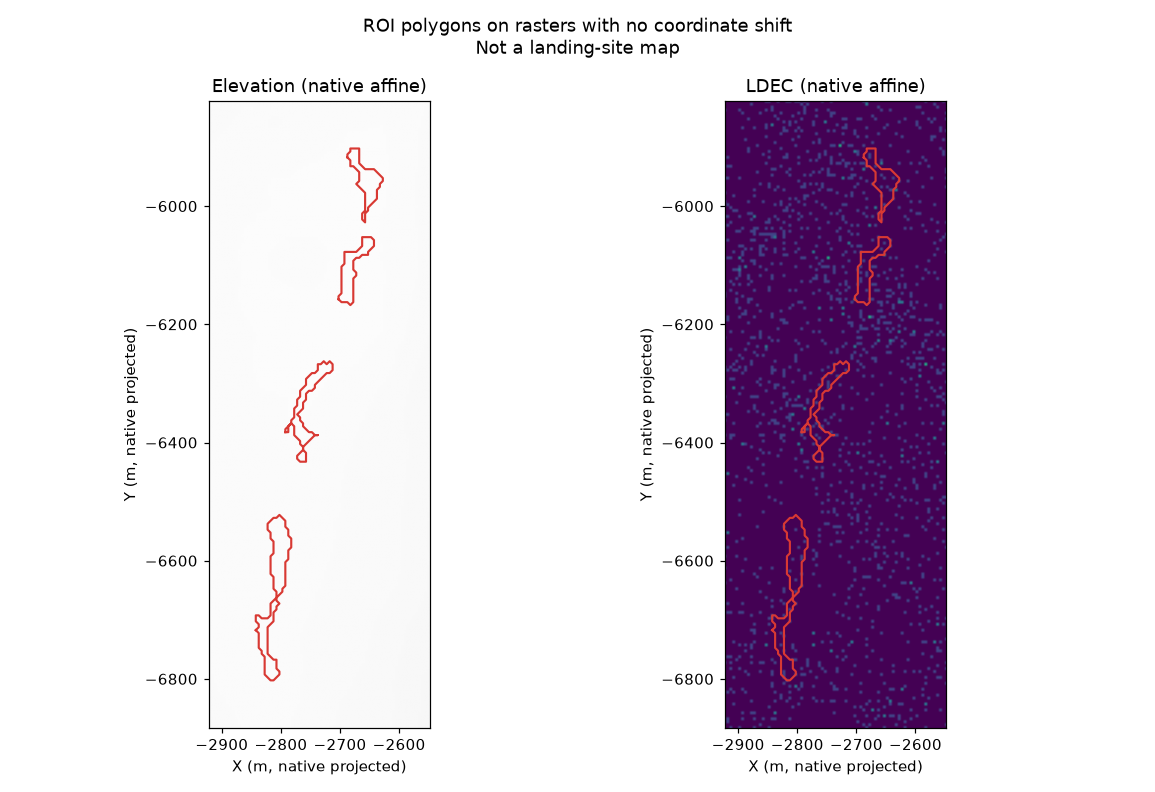

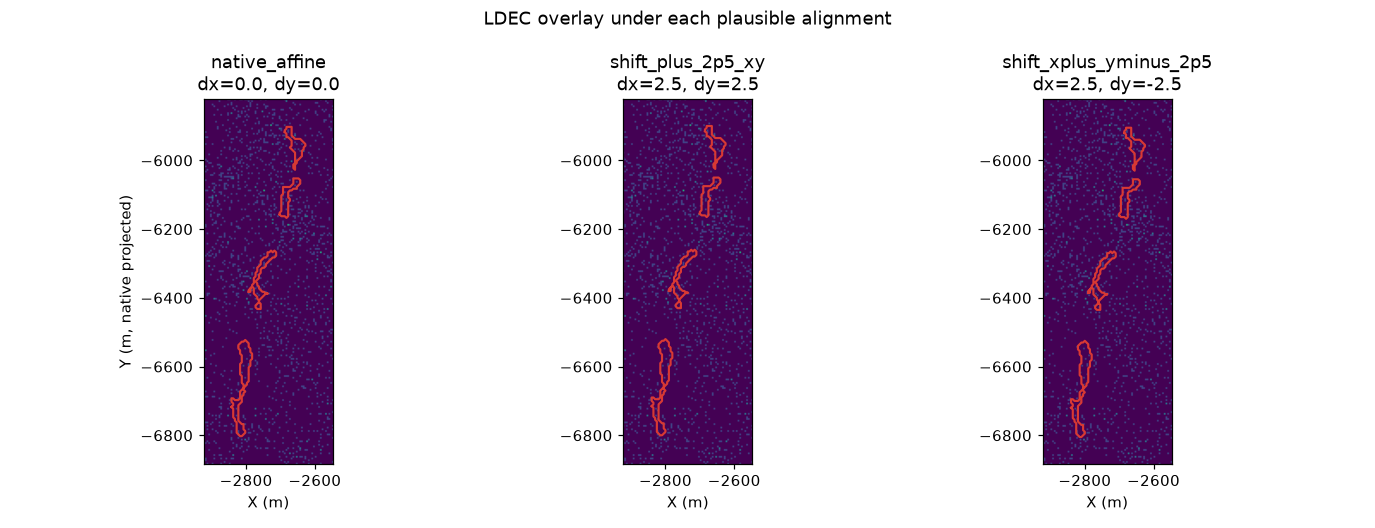

Native affine is the source-supported alignment. Shifted overlays are diagnostic only.


In [7]:
arrays = {}
with rasterio.open(raster_paths["surf"]) as src:
    arrays["surf"] = src.read(1, masked=True)
    extent = plotting_extent(src)
with rasterio.open(raster_paths["ldec"]) as src:
    arrays["ldec"] = src.read(1, masked=True)
with rasterio.open(raster_paths["toterr"]) as src:
    arrays["toterr"] = src.read(1, masked=True)
with rasterio.open(raster_paths["slp"]) as src:
    arrays["slp"] = src.read(1, masked=True)

all_poly = unary_union([feat["geometry"] for feat in features])
pad = 80.0
zoom = (all_poly.bounds[0] - pad, all_poly.bounds[2] + pad, all_poly.bounds[1] - pad, all_poly.bounds[3] + pad)

ALIGNMENTS = {
    "native_affine": (0.0, 0.0),
    "shift_plus_2p5_xy": (2.5, 2.5),
    "shift_xplus_yminus_2p5": (2.5, -2.5),
}


def show_fig(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=110, facecolor="white")
    plt.close(fig)
    display(Image(data=buf.getvalue()))


def draw_rois(ax, dx, dy, lw=1.4):
    for feat in features:
        geom = translate(feat["geometry"], xoff=dx, yoff=dy)
        xs, ys = geom.exterior.xy
        ax.plot(xs, ys, color="#d83933", linewidth=lw)


fig, axes = plt.subplots(1, 2, figsize=(10.5, 7.2))
for ax, key, title, cmap in [
    (axes[0], "surf", "Elevation (native affine)", "gray"),
    (axes[1], "ldec", "LDEC (native affine)", "viridis"),
]:
    ax.imshow(arrays[key], cmap=cmap, extent=extent, origin="upper")
    draw_rois(ax, 0.0, 0.0)
    ax.set_xlim(zoom[0], zoom[1])
    ax.set_ylim(zoom[2], zoom[3])
    ax.set_title(title)
    ax.set_xlabel("X (m, native projected)")
    ax.set_ylabel("Y (m, native projected)")
    ax.set_aspect("equal")
fig.suptitle("ROI polygons on rasters with no coordinate shift\nNot a landing-site map")
plt.tight_layout()
show_fig(fig)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.8))
for ax, (name, (dx, dy)) in zip(axes, ALIGNMENTS.items()):
    ax.imshow(arrays["ldec"], cmap="viridis", extent=extent, origin="upper")
    draw_rois(ax, dx, dy)
    ax.set_xlim(zoom[0], zoom[1])
    ax.set_ylim(zoom[2], zoom[3])
    ax.set_title(f"{name}\ndx={dx}, dy={dy}")
    ax.set_xlabel("X (m)")
    ax.set_aspect("equal")
axes[0].set_ylabel("Y (m, native projected)")
fig.suptitle("LDEC overlay under each plausible alignment")
plt.tight_layout()
show_fig(fig)
print("Native affine is the source-supported alignment. Shifted overlays are diagnostic only.")


In [8]:
def sample_arrays(x: float, y: float) -> dict:
    row, col = rasterio.transform.rowcol(gt, x, y)
    inside = 0 <= row < height and 0 <= col < width
    out = {"x_m": x, "y_m": y, "row": int(row), "col": int(col), "inside_raster": inside}
    if not inside:
        out.update(elevation_m=None, toterr_m=None, slope_deg=None, ldec=None)
        return out
    out["elevation_m"] = float(arrays["surf"][row, col])
    out["toterr_m"] = float(arrays["toterr"][row, col])
    out["slope_deg"] = float(arrays["slp"][row, col])
    out["ldec"] = float(arrays["ldec"][row, col])
    return out


roi_stats = []
ldec_gt0_candidates = []
for feat in features:
    geom = feat["geometry"]
    mask = rasterize(
        [(mapping(geom), 1)],
        out_shape=(height, width),
        transform=gt,
        fill=0,
        dtype="uint8",
        all_touched=False,
    )
    inside = mask == 1
    n_pix = int(inside.sum())
    ldec_vals = np.asarray(arrays["ldec"][inside])
    terr_vals = np.asarray(arrays["toterr"][inside])
    slp_vals = np.asarray(arrays["slp"][inside])
    surf_vals = np.asarray(arrays["surf"][inside])
    n_ldec = int((ldec_vals > 0).sum())
    roi_stats.append({
        "fid": feat["fid"],
        "n_pixels_center_in_poly": n_pix,
        "n_ldec_gt0": n_ldec,
        "frac_ldec_gt0": (n_ldec / n_pix) if n_pix else None,
        "median_toterr_m": float(np.median(terr_vals)) if n_pix else None,
        "median_slope_deg": float(np.median(slp_vals)) if n_pix else None,
        "median_elev_m": float(np.median(surf_vals)) if n_pix else None,
        "max_ldec": float(np.max(ldec_vals)) if n_pix else None,
    })
    rows, cols = np.where(inside & (np.asarray(arrays["ldec"]) > 0))
    for row, col in zip(rows, cols):
        x, y = rasterio.transform.xy(gt, int(row), int(col), offset="center")
        pt = Point(x, y)
        if not geom.covers(pt):
            continue
        ldec_gt0_candidates.append({
            "fid": feat["fid"],
            "row": int(row),
            "col": int(col),
            "x_m": float(x),
            "y_m": float(y),
            "ldec": float(arrays["ldec"][row, col]),
            "toterr_m": float(arrays["toterr"][row, col]),
            "elevation_m": float(arrays["surf"][row, col]),
            "slope_deg": float(arrays["slp"][row, col]),
        })

stats_df = pd.DataFrame(roi_stats)
display(stats_df)
print()
print("product_page_typical_roi_median_rms_z_m", "0.30-0.50")
print("site04_roi_median_toterr_range_m", (stats_df["median_toterr_m"].min(), stats_df["median_toterr_m"].max()))
print("n_ldec_gt0_pixel_centres_inside_any_roi", len(ldec_gt0_candidates))


,fid,n_pixels_center_in_poly,n_ldec_gt0,frac_ldec_gt0,median_toterr_m,median_slope_deg,median_elev_m,max_ldec
0,0,221,22,0.099548,0.425424,2.976838,1730.060303,1.0
1,1,115,17,0.147826,0.257602,2.613593,1733.277954,1.0
2,2,102,15,0.147059,0.265639,3.117097,1737.187988,2.0
3,3,101,14,0.138614,0.267844,3.548672,1736.832275,1.0



product_page_typical_roi_median_rms_z_m 0.30-0.50
site04_roi_median_toterr_range_m (np.float64(0.2576015591621399), np.float64(0.42542409896850586))
n_ldec_gt0_pixel_centres_inside_any_roi 68


In [9]:
# Point 1: keep the first-audit representative point. Temporary test point only.
audit_feat = features[0]
audit_point = audit_feat["geometry"].representative_point()
audit_sample = sample_arrays(audit_point.x, audit_point.y)
audit_record = {
    "point_id": "FID 0 / audit point",
    "selection_rule": "shapely representative_point() of FID 0; temporary unnamed test point from notebook 01",
    "fid": 0,
    "official_landing_site": False,
    "inside_fid_polygon": bool(audit_feat["geometry"].covers(audit_point)),
    **audit_sample,
}

# Point 2: deterministic LDEC>0 pixel centre inside a documented ROI, if any exist.
# Sort: highest LDEC, then lowest toterr, then lowest FID, then lowest row, then lowest col.
cand_df = pd.DataFrame(ldec_gt0_candidates)
if cand_df.empty:
    second = None
    print("No pixel centre inside any Site04 ROI has LDEC > 0 under the native affine.")
else:
    cand_df = cand_df.sort_values(
        by=["ldec", "toterr_m", "fid", "row", "col"],
        ascending=[False, True, True, True, True],
    ).reset_index(drop=True)
    print("Top LDEC>0 candidates (native affine, pixel centres covered by a ROI polygon):")
    display(cand_df.head(10))
    best = cand_df.iloc[0]
    second_point = Point(best["x_m"], best["y_m"])
    second_feat = features[int(best["fid"])]
    second = {
        "point_id": f"FID {int(best['fid'])} / LDEC>0 candidate",
        "selection_rule": "native affine; pixel centre inside a Site04_ROIs.shp polygon; LDEC>0; maximize LDEC, then minimize toterr, then lowest FID/row/col",
        "fid": int(best["fid"]),
        "official_landing_site": False,
        "inside_fid_polygon": bool(second_feat["geometry"].covers(second_point)),
        "x_m": float(best["x_m"]),
        "y_m": float(best["y_m"]),
        "row": int(best["row"]),
        "col": int(best["col"]),
        "inside_raster": True,
        "elevation_m": float(best["elevation_m"]),
        "toterr_m": float(best["toterr_m"]),
        "slope_deg": float(best["slope_deg"]),
        "ldec": float(best["ldec"]),
    }

compare = pd.DataFrame([audit_record] + ([second] if second else []))
display(compare)
print()
print("Neither point is a named landing site. Coordinates remain native projected metres. No MOON_ME/DE421 conversion is applied.")
print("FID 0 / audit point LDEC=0 is retained as an interpolated-cell example. Product-page typical ROI median RMS Z is 0.30-0.50 m; that is a site-wide median statement, not a per-pixel limit.")


Top LDEC>0 candidates (native affine, pixel centres covered by a ROI polygon):


,fid,row,col,x_m,y_m,ldec,toterr_m,elevation_m,slope_deg
0,2,1416,1269,-2652.5,-6082.5,2.0,0.169353,1736.901978,3.290690
1,1,1456,1251,-2742.5,-6282.5,1.0,0.093450,1735.100464,2.722323
2,2,1417,1265,-2672.5,-6087.5,1.0,0.101901,1737.424194,3.171077
3,2,1414,1268,-2657.5,-6072.5,1.0,0.102122,1736.901245,0.641330
4,3,1404,1268,-2657.5,-6022.5,1.0,0.104627,1737.137817,2.572605
5,1,1478,1247,-2762.5,-6392.5,1.0,0.107350,1732.870117,1.839943
6,1,1459,1250,-2747.5,-6297.5,1.0,0.113330,1735.236572,2.478282
7,1,1457,1254,-2727.5,-6287.5,1.0,0.115738,1735.137451,7.758281
8,2,1423,1263,-2682.5,-6117.5,1.0,0.115822,1738.154907,2.577925
9,1,1475,1242,-2787.5,-6377.5,1.0,0.115873,1732.322998,2.077071


,point_id,selection_rule,fid,official_landing_site,inside_fid_polygon,x_m,y_m,row,col,inside_raster,elevation_m,toterr_m,slope_deg,ldec
0,FID 0 / audit point,shapely representative_point() of FID 0; tempo...,0,False,True,-2806.25,-6660.0,1532,1238,True,1728.263184,0.837635,4.658376,0.0
1,FID 2 / LDEC>0 candidate,native affine; pixel centre inside a Site04_RO...,2,False,True,-2652.50,-6082.5,1416,1269,True,1736.901978,0.169353,3.290690,2.0



Neither point is a named landing site. Coordinates remain native projected metres. No MOON_ME/DE421 conversion is applied.
FID 0 / audit point LDEC=0 is retained as an interpolated-cell example. Product-page typical ROI median RMS Z is 0.30-0.50 m; that is a site-wide median statement, not a per-pixel limit.


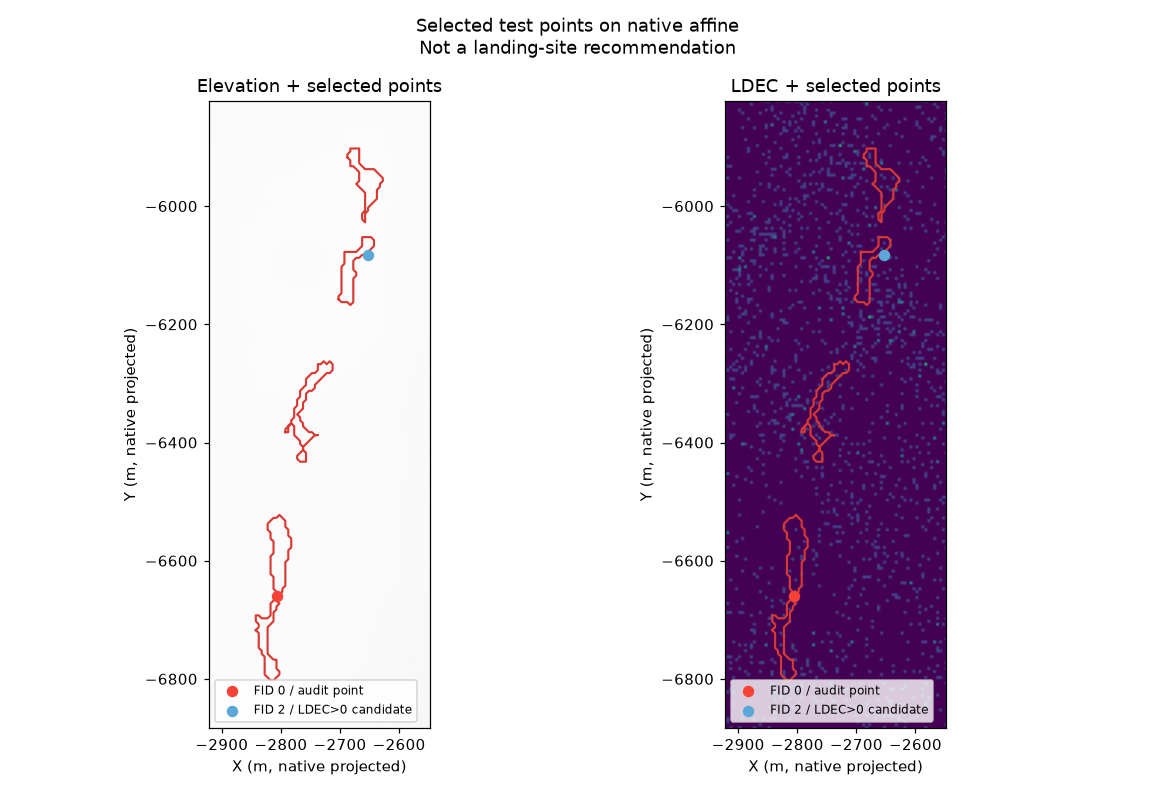

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 7.2))
points = [("FID 0 / audit point", audit_point.x, audit_point.y, "#f64137")]
if second:
    points.append((second["point_id"], second["x_m"], second["y_m"], "#5ba8d8"))
for ax, key, title, cmap in [
    (axes[0], "surf", "Elevation + selected points", "gray"),
    (axes[1], "ldec", "LDEC + selected points", "viridis"),
]:
    ax.imshow(arrays[key], cmap=cmap, extent=extent, origin="upper")
    draw_rois(ax, 0.0, 0.0)
    for label, x, y, color in points:
        ax.scatter([x], [y], c=color, s=42, zorder=5, label=label)
    ax.set_xlim(zoom[0], zoom[1])
    ax.set_ylim(zoom[2], zoom[3])
    ax.set_title(title)
    ax.set_xlabel("X (m, native projected)")
    ax.set_ylabel("Y (m, native projected)")
    ax.set_aspect("equal")
    ax.legend(loc="best", fontsize=8)
fig.suptitle("Selected test points on native affine\nNot a landing-site recommendation")
plt.tight_layout()
show_fig(fig)


In [11]:
unresolved = [
    {
        "item": "Invalid ROI polygons",
        "finding": "FID 0 has a ring self-intersection at (-2807.5, -6662.5), near the audit representative_point. FID 1 is self-intersecting and its DBF X,Y is 5 m outside the polygon. FID 2 and FID 3 are valid. The LDEC>0 candidate is in FID 2.",
        "evidence_needed": "The original GMT regionProps polygons, or a cleaned shapefile from the data provider.",
    },
    {
        "item": "ROI names",
        "finding": "Site04_ROIs.shp has only X and Y fields. FID 0..3 are archive record order, not published names.",
        "evidence_needed": "A product table mapping Site04 ROI IDs to names, or the missing regionProps GMT attributes.",
    },
    {
        "item": "avgillGT070.gmt",
        "finding": "Site04_ROIs.gmt is a dangling symlink to Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt. The tgz does not contain that file. The same URL on PGDA returned HTML, not GMT.",
        "evidence_needed": "The actual regionProps GMT file, or confirmation from Barker et al. 2021 that these polygons are the average-illumination >70% regions.",
    },
    {
        "item": "Half-pixel shift",
        "finding": "Source metadata supports the native GDAL AREA affine: GMT -r history, node_offset=1, -R equal to GeoTIFF bounds, AREA_OR_POINT=Area, and ROI vertices on the 0.5 pixel-centre phase. A half-pixel shift is not supported by those records.",
        "evidence_needed": "None for overlay in projected metres. A different registration would need an explicit author statement that the shapefile was written on a different convention.",
    },
    {
        "item": "WKT string mismatch",
        "finding": "Shapefile PRJ uses Stereographic_South_Pole / Reference meridian; GeoTIFF WKT uses Polar_Stereographic / Greenwich. Numeric parameters match (lat_0=-90, lon_0=0, R=1737400 m). No conversion was applied.",
        "evidence_needed": "An explicit statement that these two WKT labels are the MOON_ME/DE421 south-polar stereographic used by the product page, before any geographic conversion.",
    },
    {
        "item": "MOON_ME / DE421",
        "finding": "The README and product page state that frame. It is not stored as an EPSG code or FRAME name in the GeoTIFF or PRJ.",
        "evidence_needed": "A documented mapping from this unnamed sphere stereographic to a SPICE lunar frame, plus an independent check, before any lat/lon or SPICE geometry.",
    },
    {
        "item": "Interpolated elevations",
        "finding": "Product page: ~90% of 5 m pixels are interpolated. FID 0 / audit point has LDEC=0 and toterr above the 0.30-0.50 m typical ROI median range. That median is a product-page site/ROI statistic, not a per-pixel specification.",
        "evidence_needed": "None to keep the audit point as an interpolated example. A representative Site04 ROI location should use LDEC>0 and be compared against ROI median uncertainty, not treated as a named site.",
    },
]
print("Unresolved items (no names, lat/lon, or SPICE conversion invented):")
for i, item in enumerate(unresolved, start=1):
    print(f"{i}. {item['item']}: {item['finding']}")
    print(f"   Evidence needed: {item['evidence_needed']}")
print()
print("Out of scope: Sun/Earth geometry, illumination windows, landing-site ranking, live UI/API changes.")


Unresolved items (no names, lat/lon, or SPICE conversion invented):
1. Invalid ROI polygons: FID 0 has a ring self-intersection at (-2807.5, -6662.5), near the audit representative_point. FID 1 is self-intersecting and its DBF X,Y is 5 m outside the polygon. FID 2 and FID 3 are valid. The LDEC>0 candidate is in FID 2.
   Evidence needed: The original GMT regionProps polygons, or a cleaned shapefile from the data provider.
2. ROI names: Site04_ROIs.shp has only X and Y fields. FID 0..3 are archive record order, not published names.
   Evidence needed: A product table mapping Site04 ROI IDs to names, or the missing regionProps GMT attributes.
3. avgillGT070.gmt: Site04_ROIs.gmt is a dangling symlink to Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt. The tgz does not contain that file. The same URL on PGDA returned HTML, not GMT.
   Evidence needed: The actual regionProps GMT file, or confirmation from Barker et al. 2021 that these polygons are the average-illumination >70% regions.